\
# 08. レイアウト品質評価指標とマルチアルゴリズム比較ベンチマーク

このノートブックでは、`egraph` v6 が提供する **統合評価関数 `evaluate_metrics` → `MetricReport`（全 53 フィールド）** および **単体評価関数群**（ストレス／BFS・交差／角度／幾何／歪み・近傍保持／近接グラフ／RTA・コミュニティ／クラスタ分離／重なり・NOR、さらに 3D `Layout3d`・`LayoutNd` / 多様体 `ManifoldLayout2d` 対応）を網羅的に学びます。

後半では、代表的な 7 種のレイアウトアルゴリズム（`SgdSolver.full`, `StressMajorizationSolver`, `TsNetSolver`, `IbUmapSolver`, `ForceAtlas2Solver`, `YifanHuSolver`, `SgdSolver.sparse_barrier_dog`）を `dwt_1005` および 4 クラスタ確率的ブロックモデル（SBM）上で定量比較し、`matplotlib` によるレイアウト一覧・棒グラフ・正規化レーダーチャート・トレードオフ散布図を描画します。

In [ ]:
!pip install -q --pre "egraph==6.0.0b2" matplotlib-fontja

## 1. 環境設定と可視化ヘルパー関数

プロットはすべて `matplotlib` の `LineCollection` と `ax.scatter` のみを用いて描画します。

In [ ]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

# Apply Japanese font on Colab when matplotlib-fontja is installed
try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg
from egraph.interop import from_networkx

plt.rcParams["figure.dpi"] = 120
print(f"egraph version: {eg.__version__}")


def plot_layout(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    ax=None,
    *,
    labels=None,
    title: str = "",
    node_size: float = 14.0,
    edge_alpha: float = 0.18,
    edge_width: float = 0.45,
):
    '''Plot a CsrGraph and Layout2d strictly via matplotlib LineCollection + scatter.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.0, 4.5))

    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segs = []
    for u in range(graph.num_nodes):
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]:
            v_int = int(v)
            if u < v_int:
                segs.append([coords[u], coords[v_int]])
    if segs:
        ax.add_collection(LineCollection(segs, colors="#777777", linewidths=edge_width, alpha=edge_alpha, zorder=1))

    if labels is not None:
        ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c=labels, cmap="tab10", edgecolors="white", linewidths=0.25, zorder=2)
    else:
        ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c="#1f77b4", edgecolors="white", linewidths=0.25, zorder=2)

    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)
    return ax

egraph version: 6.0.0a9


\
## 2. `evaluate_metrics` と `MetricReport`（全 53 フィールド・正規化・注意点）

`evaluate_metrics(graph, layout, targets, *, labels=..., ...)` は、指定した指標のみを計算して **`MetricReport`** オブジェクト（未要求フィールドは `None`）を返します。`report.scale_normalized_stress` のような属性アクセスに加え、`report["scale_normalized_stress"]` や `report.to_dict()` / `report.keys()` にも対応します。

### 主な仕様と注意点
1. **全 53 フィールド**: 幾何・ストレス・交差・多様体歪み（`geodesic_distortion`, `torus_crossing_number` 等）・変形歪み（`prism_sigma_dist`, `prism_sigma_disp`）・NOR（`nor_oo_nni` 等 5 指標）・クラスタ／コミュニティ系（`histogram_density_measure` 含む）まで `MetricReport` に統一されています。
2. **ターゲット文字列の正規化**: 大文字・小文字を区別せず、`_`・`-`・**空白文字** をすべて除去して照合します（例: `"SNS"`, `"sweep crossing number"`, `"gcaf"`, `"rta"`, `"hdm"`）。
3. **`labels` 必須チェック**: コミュニティ系指標のいずれかを `labels=None` で呼び出すと `ValueError` が送出されます（`sprawlter_nn` は `labels` 不要で計算可能）。
4. **重み付きグラフと `ideal_edge_length`**: `graph.is_weighted == True` のとき、`evaluate_metrics(..., ideal_edge_length=s)` はグラフ辺重みを `s` 倍にスケーリングして理想辺長を評価します（`ideal_edge_lengths_scaled(g, layout, s)` と同一）。
5. **小規模グラフにおける `adjusted_patch_nig`**: デフォルトの `canvas_size=2048, patch_radius=8` では頂点数が少ない疎な配置で 1 セルあたり 1 頂点以下となり `0.0` に潰れることがあります。小規模グラフでは `patch_radius=32, canvas_size=256` 等を調整するか、`dwt_1005` のような中〜大規模グラフでデフォルト値を用います。

In [ ]:
\
# Prepare 'dwt_1005' with Leiden communities so Euclidean + cluster targets are valid at defaults
g_dwt = eg.load_dataset("dwt_1005")
leiden_dwt = eg.leiden_communities(g_dwt, seed=42)
labels_dwt = leiden_dwt.labels

l_dwt_sgd = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
eg.SgdSolver.full(g_dwt, iterations=60, seed=42).run(l_dwt_sgd)

EUCLID_45_TARGETS = [
    "scale_normalized_stress",
    "sampled_scale_normalized_stress",
    "crossing_number",
    "crossing_edges",
    "crossing_angle",
    "sampled_crossing_number",
    "crosslessness",
    "sampled_crosslessness",
    "neighborhood_preservation_1hop",
    "neighborhood_preservation_2hop",
    "sampled_np1",
    "sampled_np2",
    "gabriel_graph_property",
    "node_resolution",
    "relative_neighborhood_preservation",
    "gabriel_graph_preservation",
    "aspect_ratio",
    "angular_resolution",
    "minimum_angle",
    "minimum_angle_a1",
    "layout_degeneracy",
    "ideal_edge_lengths",
    "landmark_stratified_rta",
    "sprawlter_nn",
    "adjusted_patch_nig",
    "cluster_area_faithfulness",
    "distance_consistency",
    "distribution_consistency",
    "class_density_measure",
    "histogram_density_measure",
    "sepme_knng",
    "sepme_rng",
    "sepme_gab",
    "sepme_gong",
    "neighborhood_hit",
    "silhouette_score",
    "calinski_harabasz_score",
    "davies_bouldin_score",
    "cq_kmeans_ari",
    "cq_kmeans_ami",
    "cq_hac_hom",
    "cq_hac_ami",
    "pairwise_distance_overlap_error",
]

report = eg.evaluate_metrics(
    g_dwt,
    l_dwt_sgd,
    EUCLID_45_TARGETS,
    labels=labels_dwt,
    num_pivots=64,
    num_samples=4096,
    num_landmarks=32,
    num_triplets=50000,
    patch_radius=8,
    canvas_size=2048,
    g_max=128,
    sprawlter_node_radius=0.5,
    ideal_edge_length=1.0,
    dc_grid_size=20,
    cdm_grid_size=64,
    sepme_knng_k=2,
    neighborhood_hit_k=7,
    gong_gamma=0.35,
    kmeans_n_init=5,
    kmeans_max_iterations=100,
    num_bins=100,
    seed=42,
)
res_dict = report.to_dict()
all_53_fields = report.to_dict(include_none=True)
print(f"MetricReport total fields={len(all_53_fields)}, evaluated={len(report)} / {len(EUCLID_45_TARGETS)} targets:")
for idx, (k, v) in enumerate(res_dict.items(), 1):
    val_str = f"list(len={len(v)})" if isinstance(v, list) else f"{v:.6f}"
    print(f"  {idx:2d}. {k:<36s} = {val_str}")

# Alias normalization test (case / underscore / hyphen / whitespace insensitive)
alias_res = eg.evaluate_metrics(
    g_dwt,
    l_dwt_sgd,
    ["SNS", "NP2", "sweep crossing number", "gcaf", "rta", "mnh", "hdm", "ch", "db", "pdoe"],
    labels=labels_dwt,
    num_triplets=20000,
)
print("\nAlias resolution keys:", alias_res.keys())
print(f"Typed attribute check: alias_res.scale_normalized_stress={alias_res.scale_normalized_stress:.6f}")

# Verify ValueError when a community target is invoked without labels
try:
    eg.evaluate_metrics(g_dwt, l_dwt_sgd, ["cluster_area_faithfulness"])
except ValueError as err:
    print("Expected ValueError without labels:", err)

MetricReport total fields=53, evaluated=43 / 43 targets:
   1. scale_normalized_stress              = 0.021236
   2. sampled_scale_normalized_stress      = 0.021800
   3. crossing_number                      = 8067.000000
   4. crossing_edges                       = list(len=8067)
   5. crossing_angle                       = 2664.048945
   6. sampled_crossing_number              = 3539.320312
   7. crosslessness                        = 0.966567
   8. sampled_crosslessness                = 0.977855
   9. neighborhood_preservation_1hop       = 0.441742
  10. neighborhood_preservation_2hop       = 0.562877
  11. sampled_np1                          = 0.441742
  12. sampled_np2                          = 0.562877
  13. gabriel_graph_property               = 196.393451
  14. node_resolution                      = 512.013496
  15. relative_neighborhood_preservation   = 0.218341
  16. gabriel_graph_preservation           = 0.309707
  17. aspect_ratio                         = 0.996554
  18. 

## 3. 単体指標グループ A: ストレス & BFS 最短経路距離（5 関数）

- `scale_normalized_stress(graph, layout)` / `sampled_scale_normalized_stress(graph, layout, *, num_pivots=64, seed=42)`
- `scale_normalized_stress_from_distances(layout, distances, weights=None)`: 任意の距離行列 $D \in \mathbb{R}^{N \times N}$ に対する SNS を計算します（※ 対称行列の上三角 $i < j$ のみを参照する仕様のため、対称行列を渡してください）。
- `all_pairs_bfs(graph, unit_edge_length=1.0)` / `bfs_single_source(graph, source, unit_edge_length=1.0)`: 非連結頂点ペアは `np.inf` になります。

In [ ]:
\
g_les = eg.load_dataset("lesmis")
l_les = eg.Layout2d.init(g_les.num_nodes, seed=42)
eg.SgdSolver.full(g_les, iterations=60, seed=42).run(l_les)

d_all = eg.all_pairs_bfs(g_les, unit_edge_length=1.0)
d_src0 = eg.bfs_single_source(g_les, 0, unit_edge_length=1.0)

sns_exact = eg.scale_normalized_stress(g_les, l_les)
sns_sampled = eg.sampled_scale_normalized_stress(g_les, l_les, num_pivots=32, seed=42)
sns_from_mat = eg.scale_normalized_stress_from_distances(l_les, d_all)
sns_custom_w = eg.scale_normalized_stress_from_distances(
    l_les, d_all, weights=np.where(d_all > 0, 1.0 / np.maximum(d_all, 1.0), 0.0)
)

print(f"lesmis all_pairs_bfs shape={d_all.shape}, bfs_single_source(0)[:8]={d_src0[:8]}")
print(f"scale_normalized_stress               = {sns_exact:.6f}")
print(f"scale_normalized_stress_from_distances = {sns_from_mat:.6f} (diff={abs(sns_exact - sns_from_mat):.2e})")
print(f"sampled_scale_normalized_stress(p=32)  = {sns_sampled:.6f}")
print(f"custom 1/d weighted SNS                = {sns_custom_w:.6f}")

# Check unreachable nodes on disconnected 'poli'
g_poli = eg.load_dataset("poli")
d_poli_0 = eg.bfs_single_source(g_poli, 0)
print(f"poli bfs_single_source(0): finite={np.isfinite(d_poli_0).sum()}, inf={np.isinf(d_poli_0).sum()}")

lesmis all_pairs_bfs shape=(77, 77), bfs_single_source(0)[:8]=[0. 1. 1. 1. 1. 1. 1. 1.]
scale_normalized_stress               = 0.082605
scale_normalized_stress_from_distances = 0.082605 (diff=3.84e-15)
sampled_scale_normalized_stress(p=32)  = 0.081074
custom 1/d weighted SNS                = 0.073087
poli bfs_single_source(0): finite=2343, inf=1572


\
## 4. 単体指標グループ B: 交差数・交差角・最小角・幾何指標・歪み

このグループでは平面・トーラス・多様体上の交差・角度・幾何的バランスおよび配置の縮退・オーバーラップ除去後の歪みを計測します。

- **交差系**: `sweep_crossing_number`, `sweep_crossing_angle`, `sampled_crossing_number`, `crosslessness`, `crosslessness_from_count`, `max_crossing_pairs`, `sampled_crosslessness`, `crossing_summary`, `crossing_edges`, `torus_crossing_number`, `crossing_edges_torus`
- **角度・幾何系**: `minimum_angle`, `minimum_angle_summary` (`a1` vs `a2`), `edge_angle`, `angular_resolution`, `aspect_ratio`, `node_resolution`, `ideal_edge_lengths`, `ideal_edge_lengths_scaled`, `ideal_edge_lengths_with_unit`, `layout_degeneracy`（`excess_duplicate_ratio`, `near_collision_ratio` を含む **13 フィールド** の `LayoutDegeneracy` オブジェクトを返却；`.to_dict()` / `.keys()` 対応）
- **変形・多様体歪み系**: `prism_distortion(orig, adj)`, `prism_distortion_with_edges(orig, adj, edges)`, `geodesic_distortion(graph, manifold_layout)`

In [ ]:
\
# 1) Crossings & angles on lesmis
c_num = eg.sweep_crossing_number(g_les, l_les)
c_ang = eg.sweep_crossing_angle(g_les, l_les)
c_samp = eg.sampled_crossing_number(g_les, l_les, num_samples=4096, seed=42)
cless = eg.crosslessness(g_les, l_les)
cless_fc = eg.crosslessness_from_count(g_les, c_num)
max_cp = eg.max_crossing_pairs(g_les)
cless_samp = eg.sampled_crosslessness(g_les, l_les, num_samples=4096, seed=42)
c_sum = eg.crossing_summary(g_les, l_les)
c_edges = eg.crossing_edges(g_les, l_les)

min_ang = eg.minimum_angle(g_les, l_les)
min_ang_sum = eg.minimum_angle_summary(g_les, l_les)
ang_uv = eg.edge_angle(1.0, 0.0, 0.0, 1.0)
ang_res = eg.angular_resolution(g_les, l_les)
asp_ratio = eg.aspect_ratio(l_les)
node_res = eg.node_resolution(l_les)
iel = eg.ideal_edge_lengths(g_les, l_les)
iel_u2 = eg.ideal_edge_lengths_with_unit(g_les, l_les, 2.0)
degen = eg.layout_degeneracy(g_les, l_les)

print(f"Crossings: sweep={c_num:.0f}, sampled={c_samp:.1f}, angle_cos2={c_ang:.3f}, crosslessness={cless:.4f} (from_count={cless_fc:.4f}, max_pairs={max_cp})")
print("crossing_summary:", c_sum)
print(f"crossing_edges count={len(c_edges)}, sample[0]={c_edges[0] if c_edges else None}")
print(f"minimum_angle={min_ang:.4f}, summary={min_ang_sum}, edge_angle((1,0),(0,1))={ang_uv:.4f} rad")
print(f"angular_res={ang_res:.3f}, aspect_ratio={asp_ratio:.4f}, node_res={node_res:.4f}, iel={iel:.4f}, iel_unit2={iel_u2:.4f}")
degen_dict = degen.to_dict()
print(f"layout_degeneracy ({len(degen_dict)} keys):", list(degen_dict.keys()))

# 2) Weighted graph scaling: evaluate_metrics(..., ideal_edge_length=s) == ideal_edge_lengths_scaled(..., s)
g_weighted = eg.CsrGraph.from_edges(4, np.array([[0, 1], [1, 2], [2, 3], [3, 0]], dtype=np.uint32), weights=np.array([1.0, 1.0, 1.0, 1.0]))
l_sq = eg.Layout2d.from_coords(np.array([[0.0, 0.0], [2.0, 0.0], [2.0, 2.0], [0.0, 2.0]]))
iel_eval = eg.evaluate_metrics(g_weighted, l_sq, ["ideal_edge_lengths"], ideal_edge_length=2.0).ideal_edge_lengths
iel_scaled = eg.ideal_edge_lengths_scaled(g_weighted, l_sq, 2.0)
print(f"Weighted ideal_edge_length=2.0: evaluate_metrics={iel_eval:.4f} == ideal_edge_lengths_scaled={iel_scaled:.4f}")

# 3) Torus crossings & geodesic_distortion directly on ManifoldLayout2d
g_tor_small = eg.generate_torus_grid(4, 4)
m_tor_small = eg.ManifoldLayout2d.init("torus", g_tor_small.num_nodes, seed=42)
eg.SgdSolver.full(g_tor_small, target="manifold2d", iterations=50, seed=42).run(m_tor_small)
m_tor_eval = eg.evaluate_metrics(g_tor_small, m_tor_small, ["geodesic_distortion", "torus_crossing_number", "crossing_edges_torus"])
print(
    f"4x4 torus: torus_crossing_number={eg.torus_crossing_number(g_tor_small, m_tor_small):.1f}, "
    f"crossing_edges_torus len={len(eg.crossing_edges_torus(g_tor_small, m_tor_small))}, "
    f"geodesic_distortion={m_tor_eval.geodesic_distortion:.4f}"
)

# 4) Prism distortion after overlap removal (and via evaluate_metrics)
hw_les = np.full(g_les.num_nodes, 0.25)
hh_les = np.full(g_les.num_nodes, 0.18)
l_les_adj = eg.Layout2d.from_coords(l_les.coords(copy=True))
eg.PrismOverlapRemoval(hw_les, hh_les).run(l_les_adj)
gg_edges = eg.gabriel_graph_edges(l_les)
pd_default = eg.prism_distortion(l_les, l_les_adj)
pd_explicit = eg.prism_distortion_with_edges(l_les, l_les_adj, gg_edges)
pd_rep = eg.evaluate_metrics(g_les, l_les_adj, ["prism_distortion"], original_layout=l_les)
print(f"prism_distortion={pd_default}, via evaluate_metrics=({pd_rep.prism_sigma_dist:.4f}, {pd_rep.prism_sigma_disp:.4f}), with_edges={pd_explicit}")

Crossings: sweep=889, sampled=910.0, angle_cos2=245.567, crosslessness=0.8259 (from_count=0.8259, max_pairs=29323)
crossing_summary: CrossingSummary(count=889, angle_cos_sq_sum=245.567140)
crossing_edges count=889, sample[0]={'edge_a': 9, 'edge_b': 10, 'u1': 0, 'v1': 11, 'u2': 2, 'v2': 3, 'angle_rad': 1.5028371597278571, 'cos_sq': 0.004611342743465343}
minimum_angle=0.3671, summary=MinimumAngleSummary(a1=0.367139, a2=0.367139), edge_angle((1,0),(0,1))=1.5708 rad
angular_res=920.702, aspect_ratio=0.9412, node_res=21.3970, iel=31.2664, iel_unit2=81.5573
layout_degeneracy (13 keys): ['num_nodes', 'num_edges', 'duplicate_nodes_f32', 'duplicate_ratio_f32', 'duplicate_nodes_f64', 'duplicate_ratio_f64', 'excess_duplicate_ratio', 'near_collision_ratio', 'zero_length_edges', 'zero_length_edge_ratio', 'bbox_width', 'bbox_height', 'is_bbox_degenerate']
Weighted ideal_edge_length=2.0: evaluate_metrics=0.0000 == ideal_edge_lengths_scaled=0.0000
4x4 torus: torus_crossing_number=48.0, crossing_edges_

\
## 5. 単体指標グループ C: 近傍保持・近接グラフ・ランドマーク層別 RTA（12 関数）

- **近傍保持**: `neighborhood_preservation_1hop`, `neighborhood_preservation_2hop`, `sampled_np1`, `sampled_np2`
- **近接グラフ保持**: `drng_preservation` ($S_{\mathrm{RNG}}$), `dgg_preservation` ($S_{\mathrm{GG}}$), `gabriel_graph_property`, `gabriel_graph_edges`, `relative_neighborhood_edges`
- **ランキング順位保存（RTA）**: `landmark_stratified_rta`, `landmark_stratified_rta_detail`, `landmark_stratified_rta_from_landmarks`  
  (`landmark_stratified_rta_from_landmarks` は `all_pairs_bfs` / `bfs_single_source` が返す `np.inf` を含む `float64` 距離配列をそのまま受け取り、安全に最大距離へマッピングします。)

NP1=0.4391 (sampled=0.4391), NP2=0.6855 (sampled=0.6855)
DRNG=0.1242, DGG=0.1956, gabriel_property=34.4806, len(GG)=147, len(RNG)=97
RTA=0.9098, detail=RtaEvaluation(rta=0.909754, num_triplets=28533, is_exact=true)
RTA from precomputed MaxMin landmarks=RtaEvaluation(rta=0.909754, num_triplets=28533, is_exact=true)


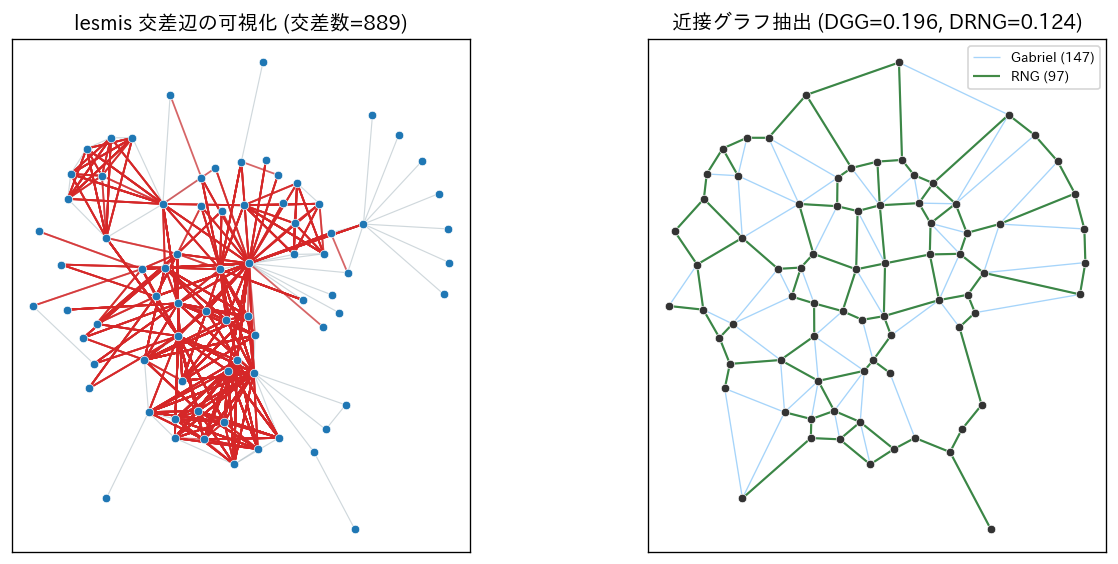

In [ ]:
\
np1 = eg.neighborhood_preservation_1hop(g_les, l_les)
np2 = eg.neighborhood_preservation_2hop(g_les, l_les)
snp1 = eg.sampled_np1(g_les, l_les, num_samples=2048, seed=42)
snp2 = eg.sampled_np2(g_les, l_les, num_samples=2048, seed=42)
drng = eg.drng_preservation(g_les, l_les)
dgg = eg.dgg_preservation(g_les, l_les)
gg_prop = eg.gabriel_graph_property(g_les, l_les)
rng_edges = eg.relative_neighborhood_edges(l_les)

rta_val = eg.landmark_stratified_rta(g_les, l_les, num_landmarks=16, num_triplets=50000, seed=42)
rta_det = eg.landmark_stratified_rta_detail(g_les, l_les, num_landmarks=16, num_triplets=50000, seed=42)

# Precomputed landmark BFS distance table (float64 with np.inf supported directly)
lm_ids = eg.select_maxmin_sp_pivots(g_les, num_pivots=16, seed=42)
lm_dists_f64 = np.vstack([eg.bfs_single_source(g_les, int(u)) for u in lm_ids])
rta_from_lm = eg.landmark_stratified_rta_from_landmarks(l_les, lm_ids, lm_dists_f64, num_triplets=50000, seed=42)

print(f"NP1={np1:.4f} (sampled={snp1:.4f}), NP2={np2:.4f} (sampled={snp2:.4f})")
print(f"DRNG={drng:.4f}, DGG={dgg:.4f}, gabriel_property={gg_prop:.4f}, len(GG)={len(gg_edges)}, len(RNG)={len(rng_edges)}")
print(f"RTA={rta_val:.4f}, detail={rta_det}")
print(f"RTA from precomputed MaxMin landmarks={rta_from_lm}")

# Visualize crossing edges (red) vs Gabriel / RNG proximity graphs on lesmis
coords_les = l_les.coords(copy=False)
indptr_les, indices_les = g_les.indptr(), g_les.indices()
all_edge_segs = [
    [coords_les[u], coords_les[int(v)]]
    for u in range(g_les.num_nodes)
    for v in indices_les[int(indptr_les[u]) : int(indptr_les[u + 1])]
    if u < int(v)
]
cross_segs = []
for ce in c_edges:
    cross_segs.append([coords_les[ce["u1"]], coords_les[ce["v1"]]])
    cross_segs.append([coords_les[ce["u2"]], coords_les[ce["v2"]]])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
axes[0].add_collection(LineCollection(all_edge_segs, colors="#b0bec5", linewidths=0.7, alpha=0.6))
if cross_segs:
    axes[0].add_collection(LineCollection(cross_segs, colors="#d62728", linewidths=1.1, alpha=0.65))
axes[0].scatter(coords_les[:, 0], coords_les[:, 1], s=26, c="#1f77b4", edgecolors="white", linewidths=0.4, zorder=3)
axes[0].set_aspect("equal")
axes[0].autoscale_view()
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_title(f"lesmis 交差辺の可視化 (交差数={int(c_num)})")

gg_segs = [[coords_les[u], coords_les[v]] for u, v in gg_edges]
rng_segs = [[coords_les[u], coords_les[v]] for u, v in rng_edges]
axes[1].add_collection(LineCollection(gg_segs, colors="#90caf9", linewidths=0.8, alpha=0.8, label=f"Gabriel ({len(gg_edges)})"))
axes[1].add_collection(LineCollection(rng_segs, colors="#2e7d32", linewidths=1.3, alpha=0.9, label=f"RNG ({len(rng_edges)})"))
axes[1].scatter(coords_les[:, 0], coords_les[:, 1], s=26, c="#333333", edgecolors="white", linewidths=0.4, zorder=3)
axes[1].set_aspect("equal")
axes[1].autoscale_view()
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_title(f"近接グラフ抽出 (DGG={dgg:.3f}, DRNG={drng:.3f})")
plt.tight_layout()
plt.show()

\
## 6. 単体指標グループ D: コミュニティ・クラスタ品質・重なり／NOR・3D 評価

グラウンドトゥルース（あるいは `leiden_communities` で抽出したラベル）に対する分離性・面積忠実性・クラスタリング整合性、および重なり除去の忠実度（`sprawlter_nn`, `sprawlter_nn_radii`, `nor_metrics`）を評価します。

- **G-CAF & Patch NIG**: `adjusted_patch_nig`, `adjusted_patch_nig_detail`, `adjusted_patch_nig_multiscale`, `cluster_area_faithfulness`, `cluster_area_faithfulness_detail(..., return_per_cluster=True)`
- **外部クラスタリング一致 & 教師なし整合性**: `partition_agreement`, `cq_kmeans`, `cq_hac`（`PartitionAgreement` 返却）
- **空間分離ベースライン（13 種）**: `distance_consistency`, `distribution_consistency`, `class_density_measure`, `histogram_density_measure`, `sepme_knng`, `sepme_rng`, `sepme_gab`, `sepme_gong`, `neighborhood_hit`, `silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score`, `pairwise_distance_overlap_error`
- **重なり & NOR & 3D 評価**: `sprawlter_nn`, `sprawlter_nn_radii`, `nor_metrics(..., graph=None | g)`（`NorMetrics` 返却・`evaluate_metrics` の `nor_metrics` ターゲットも統合済み）、3D `Layout3d` / `LayoutNd` の `evaluate_metrics`

lesmis adjusted_patch_nig: default=0.0000 -> detail=AdjustedPatchNigDetail(nig=0.543984, h_obs=0.567426, h_null=1.244311, is_degenerate=false)
lesmis multiscale: {'patch_nig_r16': 0.6182, 'patch_nig_r32': 0.544, 'patch_nig_r64': 0.4578}
dwt_1005 multiscale (defaults): {'patch_nig_r2': 0.0, 'patch_nig_r32': 0.8993, 'patch_nig_r8': 0.9034}

SBM CAF=0.9185, purity_adj=0.9549, prop_vis=0.9620
Per-cluster IDs: [0 1 2 3] caf_per_cluster: [0.9504 0.8178 0.9557 0.95  ]
partition_agreement(true, leiden): {'ari': 1.0, 'ami': 1.0, 'homogeneity': 1.0, 'completeness': 1.0, 'v_measure': 1.0, 'fmi': 1.0}
cq_kmeans: {'ari': 0.9667, 'ami': 0.9569, 'homogeneity': 0.9577, 'completeness': 0.9578, 'v_measure': 0.9578, 'fmi': 0.9748}
cq_hac   : {'ari': 0.9832, 'ami': 0.9784, 'homogeneity': 0.9788, 'completeness': 0.9789, 'v_measure': 0.9789, 'fmi': 0.9873}
DSC=0.9875, DC=1.0000, CDM=0.9985, HDM=1.0000 (standalone=1.0000), NH=0.9830, Sil=0.6808, CH=511.3, DB=0.4247, PDOE=0.0636
SepMe: knng=0.9812, rng=0.9568

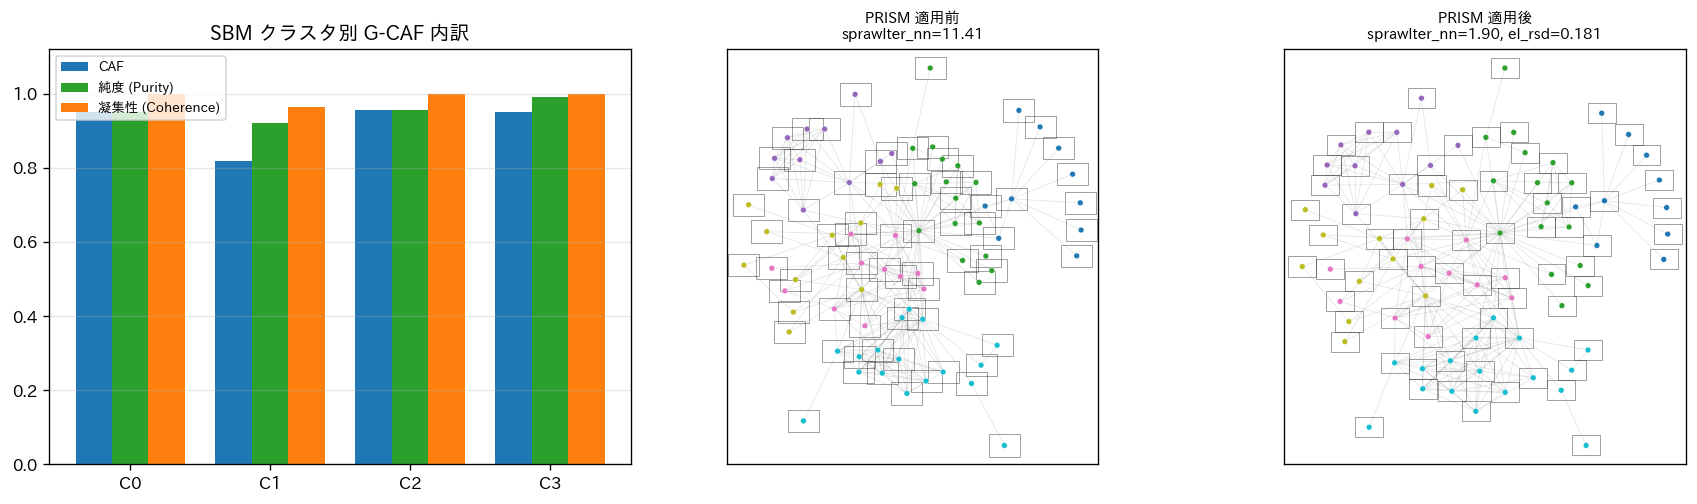

In [ ]:
\
# Build synthetic 4-cluster SBM (N=160) with planted ground-truth community labels
g_sbm_raw, sbm_raw_labels = eg.generate_sbm_graph([40, 40, 40, 40], p_intra=0.24, p_inter=0.015, seed=42)
g_sbm, lcc_idx = g_sbm_raw.largest_connected_component()
true_labels_sbm = sbm_raw_labels[lcc_idx]

# Layout SBM with IbUmapSolver for strong cluster separation
l_sbm = eg.pivot_mds_init(g_sbm, num_pivots=32, seed=42)
eg.IbUmapSolver(g_sbm, backend="ibfft", iterations=200, seed=42).run(l_sbm)

# 1) Patch NIG (detail, multiscale, tuned vs default)
leiden_les = eg.leiden_communities(g_les, seed=42).labels
pnig_les_def = eg.adjusted_patch_nig(l_les, leiden_les)
pnig_les_det = eg.adjusted_patch_nig_detail(l_les, leiden_les, patch_radius=32, canvas_size=256)
pnig_les_ms = eg.adjusted_patch_nig_multiscale(l_les, leiden_les, radii=(16, 32, 64), canvas_size=256)
pnig_dwt_ms = eg.adjusted_patch_nig_multiscale(l_dwt_sgd, labels_dwt)
print(f"lesmis adjusted_patch_nig: default={pnig_les_def:.4f} -> detail={pnig_les_det}")
print("lesmis multiscale:", {k: round(v, 4) for k, v in pnig_les_ms.items()})
print("dwt_1005 multiscale (defaults):", {k: round(v, 4) for k, v in pnig_dwt_ms.items()})

# 2) G-CAF & per-cluster breakdown
caf_val = eg.cluster_area_faithfulness(l_sbm, true_labels_sbm)
caf_det = eg.cluster_area_faithfulness_detail(l_sbm, true_labels_sbm, return_per_cluster=True)
print(f"\nSBM CAF={caf_val:.4f}, purity_adj={caf_det['purity_adj']:.4f}, prop_vis={caf_det['prop_vis']:.4f}")
print("Per-cluster IDs:", caf_det["cluster_ids"], "caf_per_cluster:", np.round(caf_det["caf_per_cluster"], 4))

# 3) Partition agreement & cluster quality baselines + histogram_density_measure
leiden_sbm = eg.leiden_communities(g_sbm, seed=42).labels
pa_leiden = eg.partition_agreement(true_labels_sbm, leiden_sbm)
cq_km = eg.cq_kmeans(l_sbm, true_labels_sbm, n_init=5, max_iterations=100, seed=42)
cq_hc = eg.cq_hac(l_sbm, true_labels_sbm)
dsc_val = eg.distance_consistency(l_sbm, true_labels_sbm)
dc_val = eg.distribution_consistency(l_sbm, true_labels_sbm, 20)
cdm_val, hdm_val = eg.class_density_measure(l_sbm, true_labels_sbm, grid_size=64)
hdm_standalone = eg.histogram_density_measure(l_sbm, true_labels_sbm, grid_size=64)
s_knn = eg.sepme_knng(l_sbm, true_labels_sbm, 2)
s_rng = eg.sepme_rng(l_sbm, true_labels_sbm)
s_gab = eg.sepme_gab(l_sbm, true_labels_sbm)
s_gong = eg.sepme_gong(l_sbm, true_labels_sbm, 0.35)
nh_val = eg.neighborhood_hit(l_sbm, true_labels_sbm, 7)
sil_val = eg.silhouette_score(l_sbm, true_labels_sbm)
ch_val = eg.calinski_harabasz_score(l_sbm, true_labels_sbm)
db_val = eg.davies_bouldin_score(l_sbm, true_labels_sbm)
pdoe_val = eg.pairwise_distance_overlap_error(l_sbm, true_labels_sbm, 100)

print("partition_agreement(true, leiden):", {k: round(v, 4) for k, v in pa_leiden.to_dict().items()})
print("cq_kmeans:", {k: round(v, 4) for k, v in cq_km.to_dict().items()})
print("cq_hac   :", {k: round(v, 4) for k, v in cq_hc.to_dict().items()})
print(
    f"DSC={dsc_val:.4f}, DC={dc_val:.4f}, CDM={cdm_val:.4f}, HDM={hdm_val:.4f} (standalone={hdm_standalone:.4f}), "
    f"NH={nh_val:.4f}, Sil={sil_val:.4f}, CH={ch_val:.1f}, DB={db_val:.4f}, PDOE={pdoe_val:.4f}"
)
print(f"SepMe: knng={s_knn:.4f}, rng={s_rng:.4f}, gab={s_gab:.4f}, gong={s_gong:.4f}")

# 4) sprawlter_nn, sprawlter_nn_radii, nor_metrics & evaluate_metrics NOR + 3D LayoutNd check
sp_before = eg.sprawlter_nn(l_les, hw_les, hh_les)
sp_after = eg.sprawlter_nn(l_les_adj, hw_les, hh_les)
sp_rad = eg.sprawlter_nn_radii(l_les_adj, hw_les)
nor_no_g = eg.nor_metrics(l_les, l_les_adj, hw_les, hh_les, graph=None)
nor_with_g = eg.nor_metrics(l_les, l_les_adj, hw_les, hh_les, graph=g_les)
nor_rep = eg.evaluate_metrics(g_les, l_les_adj, ["nor_metrics"], original_layout=l_les, sprawlter_half_widths=hw_les, sprawlter_half_heights=hh_les)
l_les_layout3d = eg.ClassicalMds(g_les, target="layout3d").generate()
rep_layout3d = eg.evaluate_metrics(g_les, l_les_layout3d, ["sns", "np2", "silhouette_score"], labels=leiden_les)
l_les_3d = eg.classical_mds(g_les, dims=3)
rep_3d = eg.evaluate_metrics(g_les, l_les_3d, ["sns", "np2", "silhouette_score"], labels=leiden_les)
print(f"\nsprawlter_nn: before={sp_before:.4f} -> after={sp_after:.4f} (radii={sp_rad:.4f})")
print("nor_metrics(graph=g):", {k: round(v, 4) for k, v in nor_with_g.to_dict().items()}, "| MetricReport.nor_oo_nni:", round(nor_rep.nor_oo_nni, 4))
print("3D Layout3d evaluate_metrics(lesmis):", {k: round(v, 4) for k, v in rep_layout3d.to_dict().items()})
print("3D LayoutNd evaluate_metrics(lesmis):", {k: round(v, 4) for k, v in rep_3d.to_dict().items()})

# Plot per-cluster CAF breakdown on SBM & PRISM overlap removal before/after on lesmis
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.3))
c_ids = caf_det["cluster_ids"]
x_c = np.arange(len(c_ids))
w = 0.26
axes[0].bar(x_c - w, caf_det["caf_per_cluster"], width=w, label="CAF", color="#1f77b4")
axes[0].bar(x_c, caf_det["purity"], width=w, label="純度 (Purity)", color="#2ca02c")
axes[0].bar(x_c + w, caf_det["coherence"], width=w, label="凝集性 (Coherence)", color="#ff7f0e")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels([f"C{int(cid)}" for cid in c_ids])
axes[0].set_ylim(0, 1.12)
axes[0].set_title("SBM クラスタ別 G-CAF 内訳")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

for ax_idx, (lay, title_str) in enumerate(
    [(l_les, f"PRISM 適用前\nsprawlter_nn={sp_before:.2f}"), (l_les_adj, f"PRISM 適用後\nsprawlter_nn={sp_after:.2f}, el_rsd={nor_with_g['el_rsd']:.3f}")],
    start=1,
):
    c_arr = lay.coords(copy=False)
    plot_layout(g_les, lay, ax=axes[ax_idx], labels=leiden_les, title=title_str, node_size=12, edge_alpha=0.2)
    for i in range(g_les.num_nodes):
        axes[ax_idx].add_patch(
            Rectangle((c_arr[i, 0] - hw_les[i], c_arr[i, 1] - hh_les[i]), 2 * hw_les[i], 2 * hh_les[i], fill=False, edgecolor="#333333", linewidth=0.5, alpha=0.55)
        )
plt.tight_layout()
plt.show()

## 7. 7 アルゴリズム横断比較ベンチマーク（`dwt_1005` & 4 クラスタ SBM）

最後に、設計思想の異なる 7 つのグラフレイアウトアルゴリズムを同一データ・同一シード条件で実行し、計算時間と多軸品質指標（`evaluate_metrics`）を定量比較します。

1. `SgdSolver.full`: 全ペア確率的勾配降下法（ストレス最小化の標準）
2. `StressMajorizationSolver`: ストレスマジョリゼーション（幾何的一貫性）
3. `TsNetSolver.pure_2hop`: 近傍保持（1+2 ホップ適応的 tsNET + FFT 反発）
4. `IbUmapSolver`: 補間ベース UMAP（高クラスタ分離）
5. `ForceAtlas2Solver`: 力学モデル ForceAtlas2（高速・ハブ強調）
6. `YifanHuSolver`: マルチレベル Barnes-Hut 力学モデル
7. `SgdSolver.sparse_barrier_dog`: $O(|E|)$ Chebyshev DoG + 3 階層スパースバリア SGD

In [ ]:
\
def run_benchmark_suite(graph: eg.CsrGraph, labels: np.ndarray, dataset_name: str):
    '''Run all 7 layout solvers from identical PivotMDS initialization and evaluate metrics.'''
    init_base = eg.pivot_mds_init(graph, num_pivots=50, seed=42).coords(copy=True)

    solver_specs = [
        ("SGD Full", lambda g, l: eg.SgdSolver.full(g, iterations=60, seed=42).run(l)),
        ("StressMaj", lambda g, l: eg.StressMajorizationSolver.from_graph(g, max_iterations=100).run(l)),
        ("TsNet 2hop", lambda g, l: eg.TsNetSolver.pure_2hop(g, backend="fit_fft", stage_iterations=(100, 100, 150), seed=42).run(l)),
        ("IbUMAP", lambda g, l: eg.IbUmapSolver(g, backend="ib_fft", iterations=200, seed=42).run(l)),
        ("ForceAtlas2", lambda g, l: eg.ForceAtlas2Solver(g, iterations=200, seed=42).run(l)),
        ("YifanHu", lambda g, l: eg.YifanHuSolver(g, max_iterations_per_level=200, seed=42).run(l)),
        ("BarrierDoG", lambda g, l: eg.SgdSolver.sparse_barrier_dog(g, iterations=60, seed=42).run(l)),
    ]

    targets = [
        "scale_normalized_stress",
        "crosslessness",
        "neighborhood_preservation_2hop",
        "landmark_stratified_rta",
        "cluster_area_faithfulness",
        "neighborhood_hit",
        "silhouette_score",
    ]

    results = []
    layouts = {}
    for name, fn in solver_specs:
        lay = eg.Layout2d.from_coords(init_base.copy())
        t0 = time.perf_counter()
        fn(graph, lay)
        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        report = eg.evaluate_metrics(
            graph,
            lay,
            targets,
            labels=labels,
            num_landmarks=32,
            num_triplets=40000,
            seed=42,
        )
        row = report.to_dict()
        row["runtime_ms"] = elapsed_ms
        row["name"] = name
        results.append(row)
        layouts[name] = lay

    print(f"\n=== Benchmark Results: {dataset_name} (N={graph.num_nodes}, E={graph.num_edges}) ===")
    print(f"{'Solver':<13} {'ms':>7} {'SNS(↓)':>8} {'CrossL(↑)':>10} {'NP2(↑)':>8} {'RTA(↑)':>8} {'CAF(↑)':>8} {'NH(↑)':>8} {'Sil(↑)':>8}")
    print("-" * 86)
    for r in results:
        print(
            f"{r['name']:<13} {r['runtime_ms']:>7.1f} {r['scale_normalized_stress']:>8.4f} "
            f"{r['crosslessness']:>10.4f} {r['neighborhood_preservation_2hop']:>8.4f} "
            f"{r['landmark_stratified_rta']:>8.4f} {r['cluster_area_faithfulness']:>8.4f} "
            f"{r['neighborhood_hit']:>8.4f} {r['silhouette_score']:>8.4f}"
        )
    return results, layouts


res_dwt, layouts_dwt = run_benchmark_suite(g_dwt, labels_dwt, "dwt_1005")
res_sbm, layouts_sbm = run_benchmark_suite(g_sbm, true_labels_sbm, "4-Cluster SBM")


=== Benchmark Results: dwt_1005 (N=1005, E=3808) ===
Solver             ms   SNS(↓)  CrossL(↑)   NP2(↑)   RTA(↑)   CAF(↑)    NH(↑)   Sil(↑)
--------------------------------------------------------------------------------------
SGD Full       2510.7   0.0212     0.9666   0.5629   0.9595   0.8036   0.8932   0.3461
StressMaj      1719.2   0.0213     0.9667   0.5610   0.9602   0.8050   0.9015   0.3509
TsNet 2hop     7208.8   0.0527     0.9690   0.6871   0.9521   0.8602   0.9183   0.4113
IbUMAP         1031.3   0.0366     0.9679   0.4586   0.9471   0.8017   0.9414   0.4257
ForceAtlas2     148.0   0.0327     0.9692   0.4918   0.9513   0.7729   0.9274   0.3572
YifanHu         282.0   0.0289     0.9687   0.5014   0.9535   0.8103   0.9279   0.3642
BarrierDoG      227.8   0.0341     0.9652   0.5366   0.9520   0.8143   0.9207   0.3851



=== Benchmark Results: 4-Cluster SBM (N=160, E=861) ===
Solver             ms   SNS(↓)  CrossL(↑)   NP2(↑)   RTA(↑)   CAF(↑)    NH(↑)   Sil(↑)
--------------------------------------------------------------------------------------
SGD Full         55.2   0.1377     0.7787   0.5548   0.8692   0.7024   0.7982   0.3300
StressMaj        60.1   0.1385     0.7844   0.5485   0.8842   0.7363   0.8250   0.3273
TsNet 2hop     6983.7   0.1866     0.8092   0.5812   0.8341   0.9376   0.9973   0.6430
IbUMAP          828.6   0.2042     0.8059   0.5601   0.7753   0.9190   0.9830   0.6806
ForceAtlas2      21.1   0.1696     0.8031   0.5740   0.8193   0.9082   0.9759   0.5960
YifanHu          32.6   0.1486     0.7907   0.5625   0.8750   0.8049   0.8973   0.4431
BarrierDoG       47.3   0.2068     0.7589   0.5053   0.8408   0.7548   0.8723   0.3203


### ベンチマーク可視化 1: `dwt_1005` の 7 手法レイアウト一覧と指標別棒グラフ

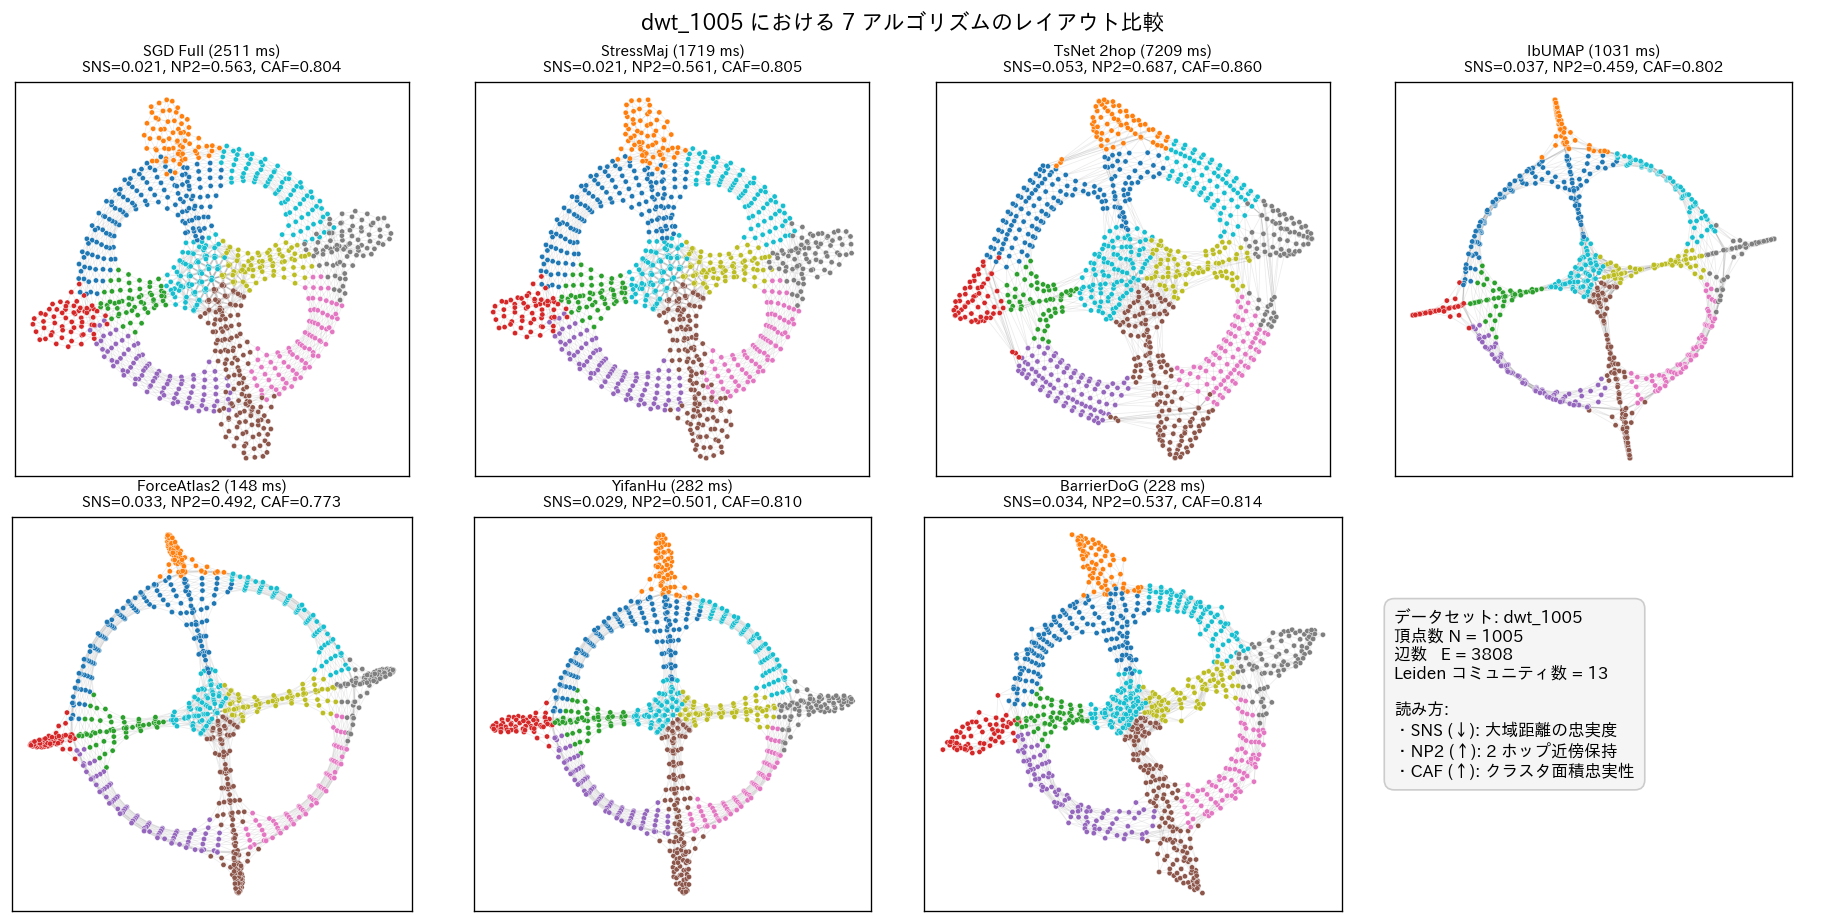

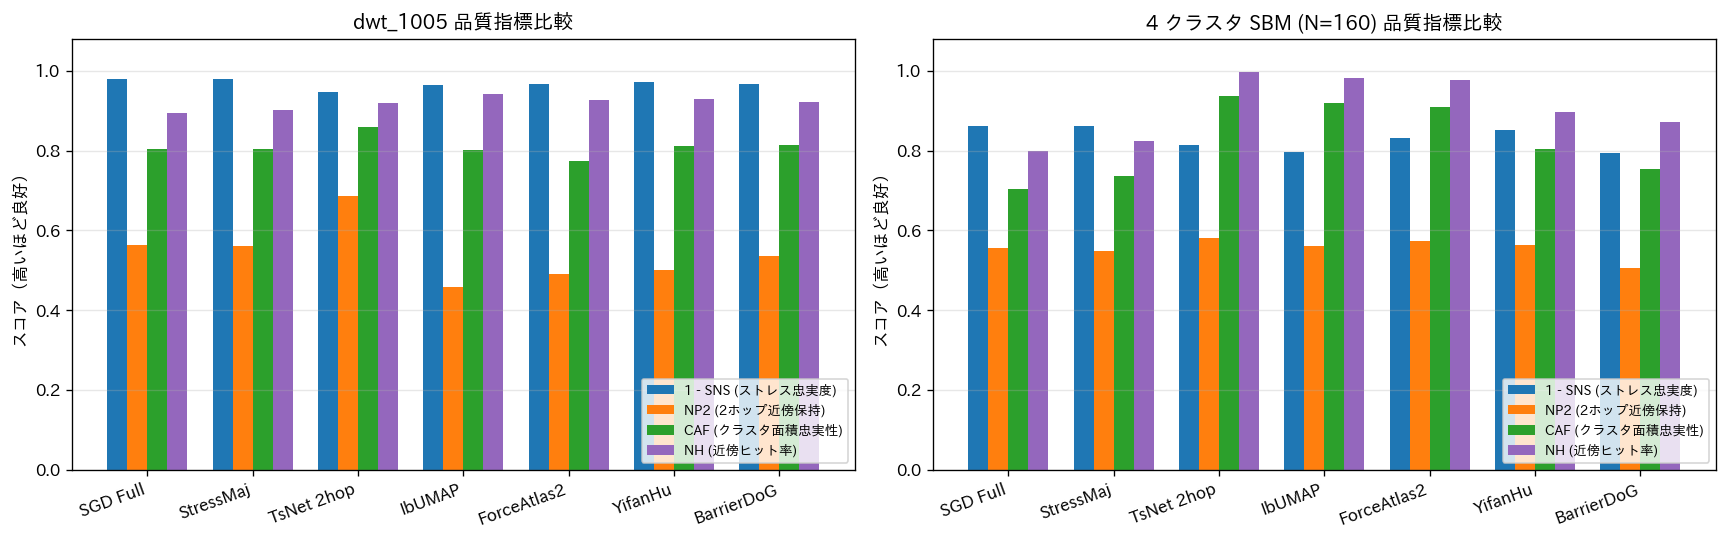

In [ ]:
\
# 1) 2x4 grid of the 7 layouts on dwt_1005 (colored by Leiden communities)
fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.8))
axes_flat = axes.ravel()
for idx, r in enumerate(res_dwt):
    name = r["name"]
    plot_layout(
        g_dwt,
        layouts_dwt[name],
        ax=axes_flat[idx],
        labels=labels_dwt,
        node_size=10.0,
        edge_alpha=0.14,
        title=f"{name} ({r['runtime_ms']:.0f} ms)\nSNS={r['scale_normalized_stress']:.3f}, NP2={r['neighborhood_preservation_2hop']:.3f}, CAF={r['cluster_area_faithfulness']:.3f}",
    )

# Use 8th panel for concise legend / benchmark summary
ax_info = axes_flat[7]
ax_info.axis("off")
ax_info.text(
    0.05,
    0.55,
    "データセット: dwt_1005\n"
    f"頂点数 N = {g_dwt.num_nodes}\n"
    f"辺数   E = {g_dwt.num_edges}\n"
    f"Leiden コミュニティ数 = {leiden_dwt.num_communities}\n\n"
    "読み方:\n"
    "・SNS (↓): 大域距離の忠実度\n"
    "・NP2 (↑): 2 ホップ近傍保持\n"
    "・CAF (↑): クラスタ面積忠実性",
    va="center",
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.6", "facecolor": "#f5f5f5", "edgecolor": "#cccccc"},
)
fig.suptitle("dwt_1005 における 7 アルゴリズムのレイアウト比較", fontsize=13)
plt.tight_layout()
plt.show()

# 2) Grouped bar charts comparing key metrics across dwt_1005 and 4-Cluster SBM
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
solver_names = [r["name"] for r in res_dwt]
x = np.arange(len(solver_names))
bw = 0.19

for ax, res_list, ds_title in [
    (axes[0], res_dwt, "dwt_1005 品質指標比較"),
    (axes[1], res_sbm, "4 クラスタ SBM (N=160) 品質指標比較"),
]:
    sns_inv = [1.0 - r["scale_normalized_stress"] for r in res_list]
    np2_vals = [r["neighborhood_preservation_2hop"] for r in res_list]
    caf_vals = [r["cluster_area_faithfulness"] for r in res_list]
    nh_vals = [r["neighborhood_hit"] for r in res_list]

    ax.bar(x - 1.5 * bw, sns_inv, width=bw, label="1 - SNS (ストレス忠実度)", color="#1f77b4")
    ax.bar(x - 0.5 * bw, np2_vals, width=bw, label="NP2 (2ホップ近傍保持)", color="#ff7f0e")
    ax.bar(x + 0.5 * bw, caf_vals, width=bw, label="CAF (クラスタ面積忠実性)", color="#2ca02c")
    ax.bar(x + 1.5 * bw, nh_vals, width=bw, label="NH (近傍ヒット率)", color="#9467bd")
    ax.set_xticks(x)
    ax.set_xticklabels(solver_names, rotation=20, ha="right")
    ax.set_ylim(0.0, 1.08)
    ax.set_ylabel("スコア（高いほど良好）")
    ax.set_title(ds_title)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

### ベンチマーク可視化 2: 正規化レーダーチャートとトレードオフ散布図（`SNS` vs `NP2`・`CAF` vs 計算時間）

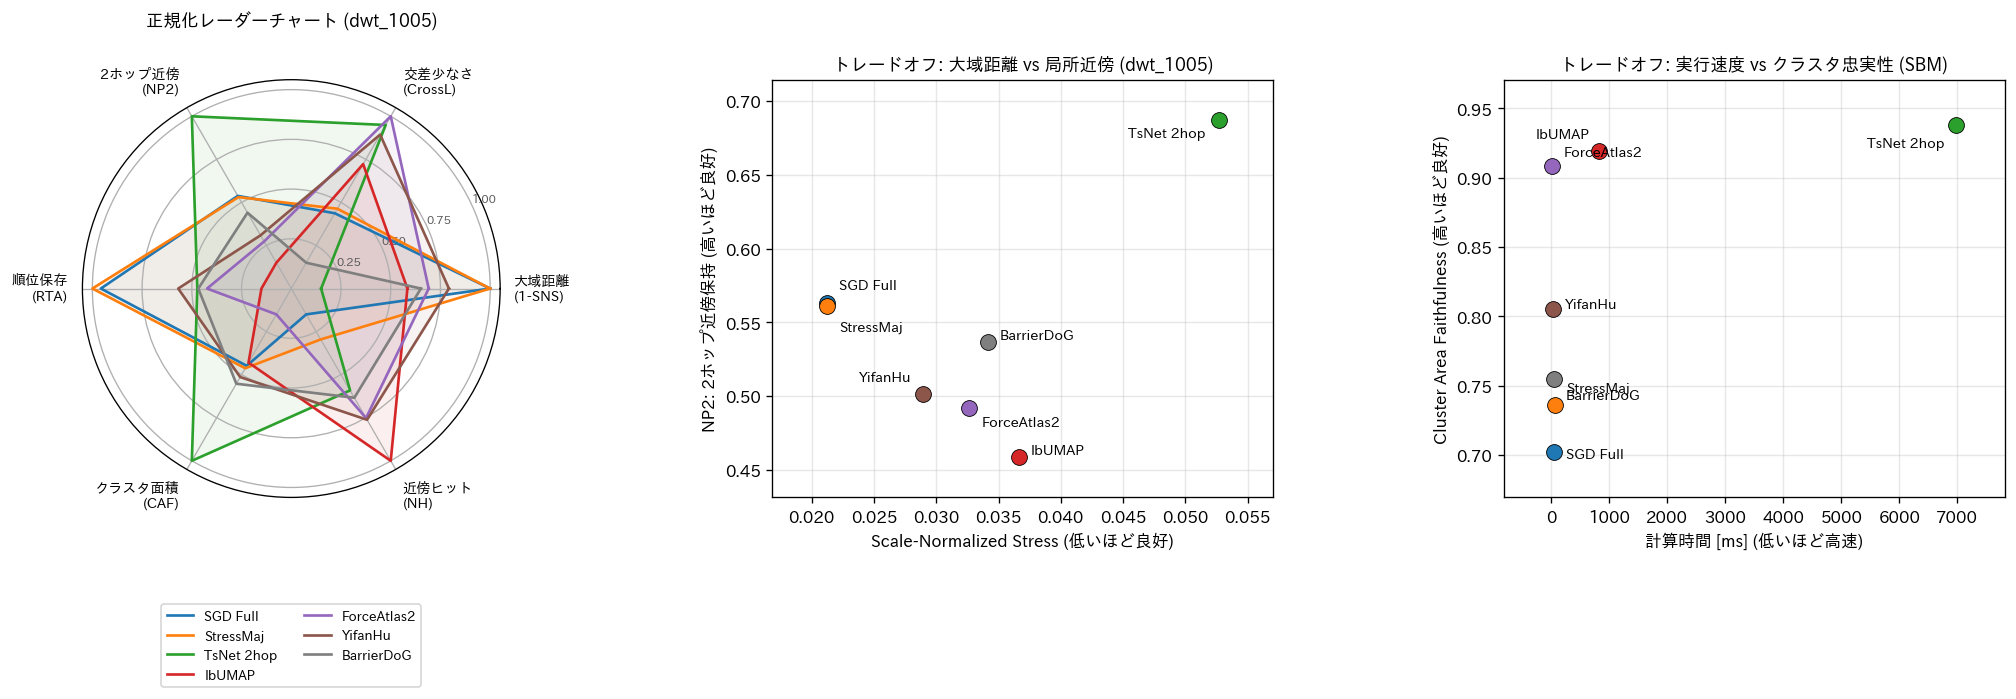

In [ ]:
# 1) Normalized radar chart on dwt_1005 (6 axes, min-max scaled across solvers so higher is better)
radar_axes = [
    ("大域距離\n(1-SNS)", lambda r: 1.0 - r["scale_normalized_stress"]),
    ("交差少なさ\n(CrossL)", lambda r: r["crosslessness"]),
    ("2ホップ近傍\n(NP2)", lambda r: r["neighborhood_preservation_2hop"]),
    ("順位保存\n(RTA)", lambda r: r["landmark_stratified_rta"]),
    ("クラスタ面積\n(CAF)", lambda r: r["cluster_area_faithfulness"]),
    ("近傍ヒット\n(NH)", lambda r: r["neighborhood_hit"]),
]

raw_mat = np.array([[fn(r) for _, fn in radar_axes] for r in res_dwt], dtype=float)
col_min = raw_mat.min(axis=0)
col_max = raw_mat.max(axis=0)
norm_mat = (raw_mat - col_min) / np.maximum(col_max - col_min, 1e-12)
# Map to [0.15, 1.0] for clean polygon visibility
norm_mat = 0.15 + 0.85 * norm_mat

angles = np.linspace(0.0, 2.0 * np.pi, len(radar_axes), endpoint=False).tolist()
angles_closed = angles + [angles[0]]

fig = plt.figure(figsize=(17.6, 5.9))
fig.subplots_adjust(left=0.05, right=0.98, bottom=0.25, top=0.84, wspace=0.46)

# Left: Radar chart with angle-aware outer label placement
ax_rad = fig.add_subplot(131, polar=True)
palette = plt.cm.tab10(np.linspace(0, 0.7, len(res_dwt)))
for idx, r in enumerate(res_dwt):
    vals = norm_mat[idx].tolist() + [norm_mat[idx, 0]]
    ax_rad.plot(angles_closed, vals, linewidth=1.6, color=palette[idx], label=r["name"])
    ax_rad.fill(angles_closed, vals, color=palette[idx], alpha=0.07)

ax_rad.set_xticks(angles)
ax_rad.set_xticklabels([])
ax_rad.set_ylim(0.0, 1.05)
ax_rad.set_yticks([0.25, 0.5, 0.75, 1.0])
ax_rad.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=7, color="#555555")
ax_rad.set_rlabel_position(25)

for angle, (lbl, _) in zip(angles, radar_axes):
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    ha = "center" if abs(cos_a) < 0.15 else ("left" if cos_a > 0 else "right")
    va = "center" if abs(sin_a) < 0.15 else ("bottom" if sin_a > 0 else "top")
    ax_rad.text(angle, 1.12, lbl, fontsize=8.5, ha=ha, va=va, clip_on=False)

ax_rad.set_title("正規化レーダーチャート (dwt_1005)", pad=32, fontsize=10.5)
ax_rad.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=8)

# Middle: Trade-off scatter (SNS vs NP2 on dwt_1005) with per-solver offsets
sc1_offsets = {
    "SGD Full": (7, 7, "left", "bottom"),
    "StressMaj": (7, -9, "left", "top"),
    "TsNet 2hop": (-8, -4, "right", "top"),
    "IbUMAP": (7, 4, "left", "center"),
    "ForceAtlas2": (7, -5, "left", "top"),
    "YifanHu": (-7, 6, "right", "bottom"),
    "BarrierDoG": (7, 4, "left", "center"),
}
ax_sc1 = fig.add_subplot(132)
for idx, r in enumerate(res_dwt):
    x_val, y_val = r["scale_normalized_stress"], r["neighborhood_preservation_2hop"]
    ax_sc1.scatter(x_val, y_val, s=90, color=palette[idx], edgecolors="black", linewidths=0.5, zorder=3)
    dx, dy, ha, va = sc1_offsets.get(r["name"], (6, 4, "left", "center"))
    ax_sc1.annotate(
        r["name"],
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha=ha,
        va=va,
        fontsize=8.5,
    )
ax_sc1.margins(x=0.14, y=0.12)
ax_sc1.set_xlabel("Scale-Normalized Stress (低いほど良好)")
ax_sc1.set_ylabel("NP2: 2ホップ近傍保持 (高いほど良好)")
ax_sc1.set_title("トレードオフ: 大域距離 vs 局所近傍 (dwt_1005)", fontsize=10.5)
ax_sc1.grid(alpha=0.3)

# Right: Trade-off scatter (Runtime vs CAF on SBM) with per-solver offsets
sc2_offsets = {
    "SGD Full": (7, -2, "left", "center"),
    "StressMaj": (7, 6, "left", "bottom"),
    "TsNet 2hop": (-7, -7, "right", "top"),
    "IbUMAP": (-6, 6, "right", "bottom"),
    "ForceAtlas2": (7, 4, "left", "bottom"),
    "YifanHu": (7, 3, "left", "center"),
    "BarrierDoG": (7, -6, "left", "top"),
}
ax_sc2 = fig.add_subplot(133)
for idx, r in enumerate(res_sbm):
    x_val, y_val = r["runtime_ms"], r["cluster_area_faithfulness"]
    ax_sc2.scatter(x_val, y_val, s=90, color=palette[idx], edgecolors="black", linewidths=0.5, zorder=3)
    dx, dy, ha, va = sc2_offsets.get(r["name"], (6, 4, "left", "center"))
    ax_sc2.annotate(
        r["name"],
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha=ha,
        va=va,
        fontsize=8.5,
    )
ax_sc2.margins(x=0.12, y=0.14)
ax_sc2.set_xlabel("計算時間 [ms] (低いほど高速)")
ax_sc2.set_ylabel("Cluster Area Faithfulness (高いほど良好)")
ax_sc2.set_title("トレードオフ: 実行速度 vs クラスタ忠実性 (SBM)", fontsize=10.5)
ax_sc2.grid(alpha=0.3)

plt.show()
